# The Galápagos plant species–area relationship

A complete analysis with `sars`, from the raw island data to a model-averaged
curve with confidence intervals and a check for a small-island effect. Every step
is one function call, and every result is a plain object you can inspect, so the
same sequence works for your own data (see the end).

The data are Preston's (1962) counts of vascular plant species on 16 Galápagos
islands, with island areas in km², as shipped in the R `sars` package (Isabela is
excluded). They are bundled with the package as `load_galap()`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sars

## The data

A `sars` dataset is a `pandas.DataFrame` with two columns, `area` and `species`.

In [2]:
galap = sars.load_galap()
galap.sort_values("area").reset_index(drop=True)

,area,species
0,0.52,48
1,2.33,7
2,2.59,52
3,4.66,14
4,4.84,42
5,11.40,22
6,18.39,103
7,19.42,48
8,46.62,79
9,51.80,119


In [3]:
galap.describe().T

,count,mean,std,min,25%,50%,75%,max
area,16.0,194.8600,304.251296,0.52,4.795,33.02,250.5825,1007.51
species,16.0,106.4375,100.327443,7.00,45.750,65.50,137.5000,319.00


Area spans more than three orders of magnitude, so the natural view is a log–log plot.
The spread at small areas is already visible: islands under 10 km² have anywhere from
7 to 52 species.

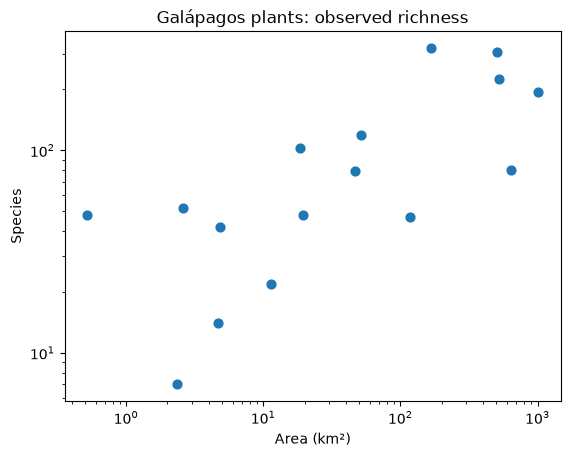

In [4]:
ax = galap.plot.scatter(x="area", y="species", s=40)
ax.set(xscale="log", yscale="log", xlabel="Area (km²)", ylabel="Species",
       title="Galápagos plants: observed richness")
plt.show()

## One model: the power law

Arrhenius' power law, $S = cA^z$, is the classic SAR model. `sar_power()` fits it by
non-linear least squares and returns a `SARFit` with the parameters, goodness of fit
and information criteria.

In [5]:
power = sars.sar_power(galap)
power

SARFit(model='power', c=33.1804  z=0.2832, R²=0.4912, AICc=189.03)

In [6]:
print("parameters:", {k: round(float(v), 4) for k, v in power.params.items()})
print("R²:", round(power.r_squared, 4), " AICc:", round(power.aicc, 2),
      " converged:", power.converged)

parameters: {'c': 33.1804, 'z': 0.2832}
R²: 0.4912  AICc: 189.03  converged: True


`predict()` evaluates the fitted curve at any area, here for islands of 1, 10, 100
and 1000 km².

In [7]:
areas = np.array([1.0, 10.0, 100.0, 1000.0])
pd.DataFrame({"area": areas, "predicted species": power.predict(areas).round(1)})

,area,predicted species
0,1.0,33.2
1,10.0,63.7
2,100.0,122.2
3,1000.0,234.6


`plot_fit()` draws the fitted curve over the observations, on linear or log axes, and
`plot_residuals()` shows residuals against fitted values. The power law explains about
half the variance here; the residual plot shows why, with the small islands scattering
widely around the curve.

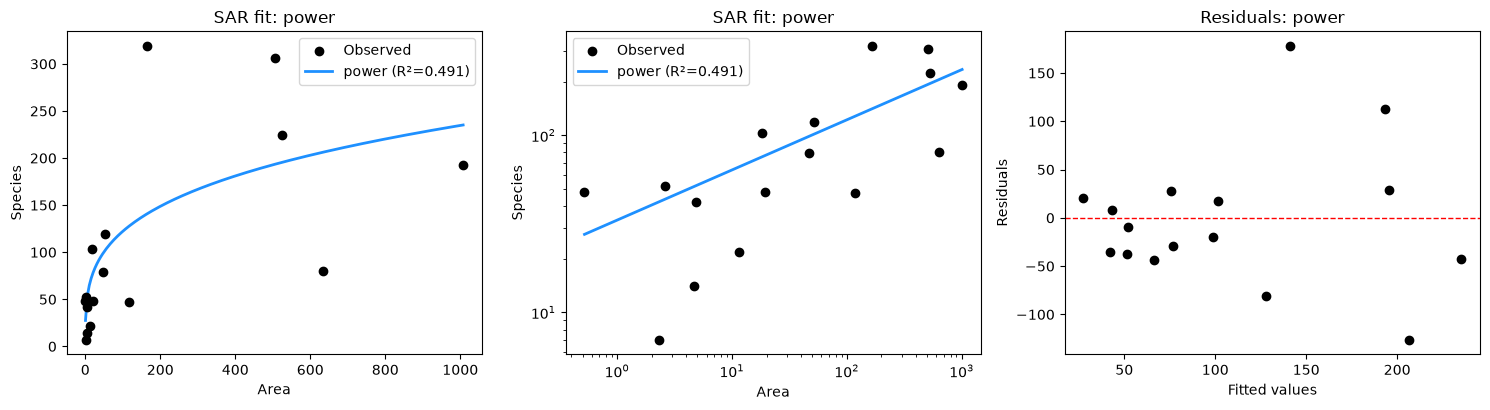

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sars.plot_fit(power, ax=axes[0])
sars.plot_fit(power, ax=axes[1], log=True)
sars.plot_residuals(power, ax=axes[2])
fig.tight_layout()
plt.show()

## All twenty models

There is no reason to assume the power law is the right shape. `sar_multi()` fits every
model in the package and returns a `MultiSARFit` whose `summary` ranks them by AICc,
with Akaike weights (the relative support for each model, summing to one), the shape of
each fitted curve and, for models that have one, the asymptote.

In [9]:
multi = sars.sar_multi(galap)
cols = ["model", "R2", "AICc", "delta_AICc", "weight", "shape", "asymptote"]
multi.summary[cols].round(3)

,model,R2,AICc,delta_AICc,weight,shape,asymptote
0,negexpo,0.557,186.832,0.000,0.194,convex,207.926
1,monod,0.545,187.246,0.414,0.158,convex,222.342
2,koba,0.521,188.073,1.241,0.104,convex,NaN
3,power,0.491,189.031,2.199,0.065,convex,NaN
4,loga,0.486,189.191,2.359,0.060,convex,NaN
5,p1,0.589,189.246,2.414,0.058,convex,NaN
6,gompertz,0.585,189.393,2.561,0.054,sigmoid,210.850
7,asymp,0.578,189.672,2.840,0.047,convex,209.120
8,chapman,0.565,190.171,3.339,0.036,sigmoid,208.016
9,epm1,0.564,190.186,3.354,0.036,convex,NaN


Several convex models fit about equally well, and the best has a weight well under 0.5:
the data don't single out one functional form. That is the usual situation with a
handful of islands, and the reason for the next step. `plot_multi()` overlays the top
models; `fits` holds the individual `SARFit` objects if you need one of them.

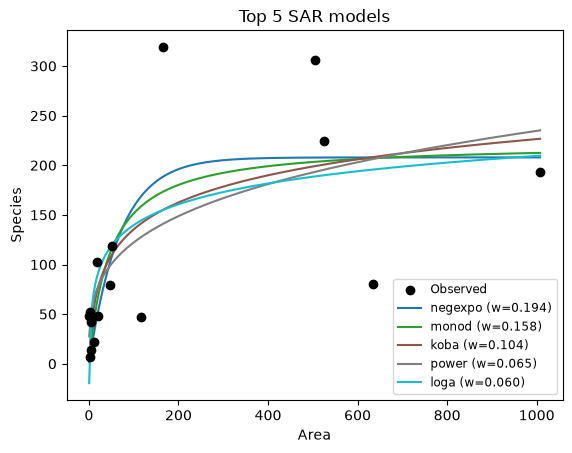

In [10]:
sars.plot_multi(multi, top_n=5)
plt.show()

## Model averaging

Rather than choosing a winner, `sar_average()` weights each model's prediction by its
Akaike weight. The `AveragedSAR` it returns has the weights and a `predict()` like a
single fit. Compared with the power law alone, the averaged curve is lower at the
smallest areas, where the leading asymptotic models pass near the origin, and flatter
at the largest.

In [11]:
avg = sars.sar_average(galap)
weights = pd.Series(avg.weights, name="weight").sort_values(ascending=False)
weights.head(8).round(3)

negexpo     0.194
monod       0.158
koba        0.104
power       0.065
loga        0.060
p1          0.058
gompertz    0.054
asymp       0.047
Name: weight, dtype: float64

In [12]:
pd.DataFrame({
    "area": areas,
    "power law": power.predict(areas).round(1),
    "model average": avg.predict(areas).round(1),
})

,area,power law,model average
0,1.0,33.2,10.2
1,10.0,63.7,41.9
2,100.0,122.2,149.1
3,1000.0,234.6,208.7


## Bootstrap confidence intervals

`bootstrap_ci()` resamples the islands, refits and re-averages on each resample, and
returns percentile intervals for the averaged curve on a grid of areas. The default
`method="fast"` warm-starts every refit from the parameters fitted to the original data;
`method="full"` repeats the whole grid search per resample and is much slower. Pass a
seeded `numpy` generator for a reproducible result. Three hundred resamples take about
a minute here; use more for a publication figure.

In [13]:
ci = sars.bootstrap_ci(galap, n_boot=300, rng=np.random.default_rng(1))
print(f"{ci.n_boot} resamples, {ci.n_models_attempted} models each, {int(ci.conf * 100)}% intervals")

300 resamples, 20 models each, 95% intervals


In [14]:
rows = [np.argmin(abs(ci.area_grid - a)) for a in (10.0, 100.0, 500.0, 1000.0)]
at = ci.area_grid[rows]
pd.DataFrame({
    "area": at.round(1),
    "lower": ci.lower[rows].round(1),
    "model average": avg.predict(at).round(1),
    "upper": ci.upper[rows].round(1),
})

,area,lower,model average,upper
0,10.7,0.2,43.7,63.0
1,102.2,61.5,150.3,296.9
2,498.9,116.7,204.6,326.0
3,997.3,3.4,208.6,512.9


`plot_average()` draws the averaged curve, and shades the interval when given the
bootstrap result. The band is wide and ragged, and honestly so: with sixteen islands, a
resample that repeats a few of them lets the three- and four-parameter models fit
wildly, and the gap between the mid-sized and the largest islands is where that shows.
More islands, or a smaller candidate set chosen on biological grounds, narrows it. Use
the averaged fit's own prediction as the central curve rather than the bootstrap
`mean`, which a few divergent resamples dominate.

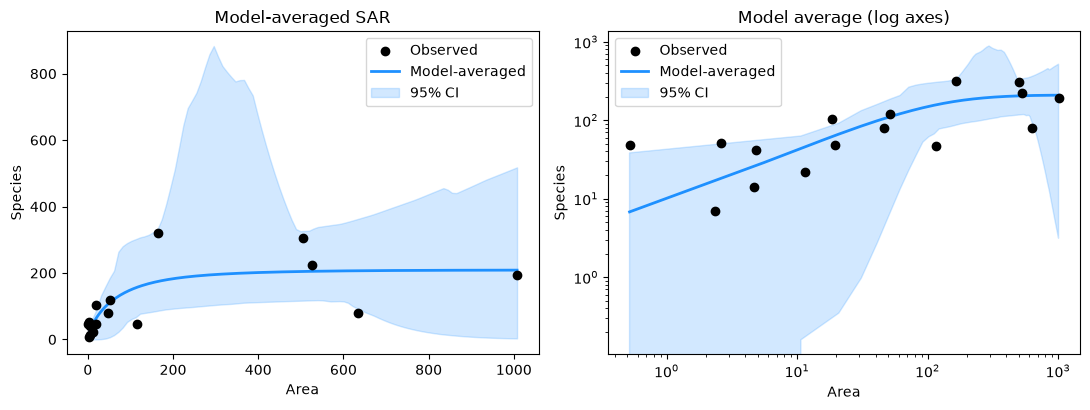

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sars.plot_average(avg, boot=ci, ax=axes[0])
sars.plot_average(avg, boot=ci, ax=axes[1])
axes[1].set(xscale="log", yscale="log", title="Model average (log axes)")
fig.tight_layout()
plt.show()

## Is there a small-island effect?

Below some area, richness may stop responding to area at all: the small-island effect.
`sar_threshold()` fits piecewise models to species against log(area) and compares them
with a plain log-linear fit by AICc. `ContOne` is a continuous two-slope line with one
breakpoint; `ZslopeOne` has a flat left segment, the small-island effect proper;
`Linear` is the no-breakpoint baseline. Pass `log_area=False` to fit on area itself.

In [16]:
th = sars.sar_threshold(galap)
print(th)
th.summary.round(3)

ThresholdFit(best='Linear')


,model,breakpoint,breakpoint_area,AIC,AICc,BIC,R2
0,Linear,NaN,NaN,187.191,189.191,189.509,0.486
1,ZslopeOne,2.052,7.781,187.580,191.216,190.670,0.535
2,ContOne,1.852,6.370,189.529,195.529,193.392,0.537


The models are fitted on the natural log of area, so `breakpoint` is on that scale;
`breakpoint_area` beside it is the same point in km² (the result has a `breakpoint_area`
attribute too). For the Galápagos plants the log-linear model wins; the flat-then-slope
model trails it by two AICc units and the two-slope model by six, with only sixteen
islands behind them. No clear small-island effect in these data.

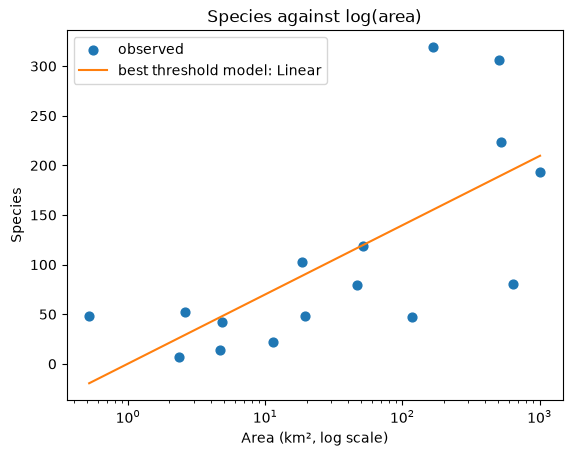

In [17]:
grid = np.geomspace(galap["area"].min(), galap["area"].max(), 200)
ax = galap.plot.scatter(x="area", y="species", s=40, label="observed")
ax.plot(grid, th.predict(grid), color="C1", label=f"best threshold model: {th.best_model}")
ax.set(xscale="log", xlabel="Area (km², log scale)", ylabel="Species",
       title="Species against log(area)")
ax.legend()
plt.show()

## Your own data

Any `DataFrame` with `area` and `species` columns works in place of `galap`, and the
I/O adapters build one from a CSV with other column names, a GeoDataFrame (area from
the geometries) or a pyiNaturalist summary:

```python
islands = sars.from_csv("islands.csv", area_col="island_area", species_col="richness")
multi = sars.sar_multi(islands)
```

Two things to keep in mind. Fitting twenty non-linear models with a multi-start search
takes a few seconds per call, and the bootstrap repeats it per resample. And the
threshold models need at least seven observations to place a breakpoint; with fewer,
only the linear baseline is fitted and a warning says so.

### References

- Arrhenius O (1921). Species and area. *Journal of Ecology*, 9, 95–99.
- Matthews TJ, Triantis KA, Whittaker RJ, Guilhaumon F (2019). sars: an R package for
  fitting, evaluating and comparing species–area relationship models. *Ecography*, 42,
  1446–1455.
- Matthews TJ, Rigal F (2021). Thresholds and the species–area relationship. *Frontiers
  of Biogeography*, 13, e49404.
- Preston FW (1962). The canonical distribution of commonness and rarity. *Ecology*, 43,
  185–215, 410–432.